In [169]:
import papermill as pm
import scrapbook as sb
from tqdm.notebook import tqdm
import numpy as np
import matplotlib.pyplot as plt
import statistics
from scipy.stats import norm


In [141]:
n_runs = 42

RES_pf  = []
RES_B   = []
RES_sr  = []
RES_rew = []
RES_MSD = []

for i in range(n_runs):
    output_file = f'pm_velocity{i}.ipynb'
    nb = sb.read_notebook(output_file)
    RES_pf.append(nb.scraps['res_pf'].data)
    RES_B.append(nb.scraps['res_B'].data)
    #RES_sr.append(nb.scraps['res_sr'].data)
    RES_rew.append(nb.scraps['res_rew'].data)
    RES_MSD.append(nb.scraps['res_MSD'].data)

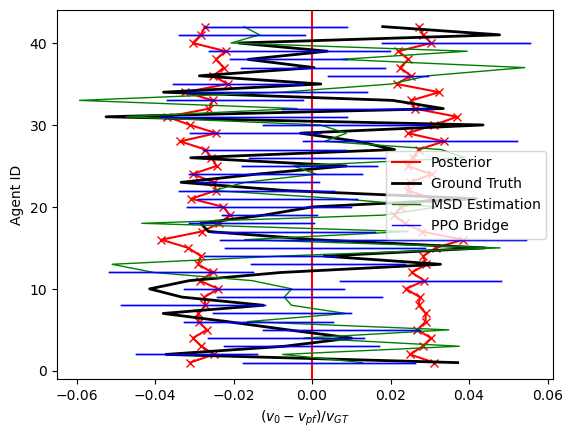

In [156]:
plt.axvline(0, c='r', label="Posterior")

std_pf = np.array([d['std'] for d in RES_pf])
std_B = np.array([d['std'] for d in RES_B])

plt.plot(std_pf, range(1, len(std_pf)+1), '-xr')
plt.plot(-std_pf, range(1, len(std_pf)+1), '-xr')

mean_pf = np.array([d['mean'] for d in RES_pf])
plt.plot(1-mean_pf, range(1, len(std_pf)+1), '-k', lw=2, label="Ground Truth")

mean_MSD = np.array([d['mean'] for d in RES_MSD])
std_MSD = np.array([d['std'] for d in RES_MSD])
plt.plot(mean_MSD - mean_pf, range(1, len(mean_MSD)+1), 'g', lw=1, label="MSD Estimation")
#plt.plot(mean_MSD - mean_pf + std_MSD, range(1, len(mean_MSD)+1), 'xg', lw=1)
#plt.plot(mean_MSD - mean_pf - std_MSD, range(1, len(mean_MSD)+1), 'xg', lw=1)


#for i, r in enumerate(RES_pf):
#    mean = r['mean']
#    ci_mean = r['ci_mean']
#    stdev = r['std']
#    pos = i - 0.1 + 1
#    plt.plot([mean - stdev, mean + stdev], [pos, pos], '-', lw=2, c='orange')  # Whiskers
#    plt.plot(ci_mean, [pos, pos], '-', lw=8, c='orange')  # Mean point

for i, (r_B, r_pf) in enumerate(zip(RES_B, RES_pf)):
    mean = r_B['mean'] - r_pf['mean']
    ci_mean = np.array(r_B['ci_mean']) - r_pf['mean']
    stdev = r_B['std']
    pos = i + 1
    label = "PPO Bridge" if i==0 else None
    plt.plot([mean - stdev, mean + stdev], [pos, pos], 'b-', lw=1, label=label)  # Whiskers
    plt.plot(ci_mean, [pos, pos], '-b', lw=0)  # Mean point

    mean = r_B['mean'] - r_pf['mean']
    ci_mean = np.array(r_B['ci_mean']) - r_pf['mean']
    stdev = r_B['std']
    pos = i + 1
    plt.plot([mean - stdev, mean + stdev], [pos, pos], 'b-', lw=1)  # Whiskers
    plt.plot(ci_mean, [pos, pos], '-b', lw=0)  # Mean point


#plt.axvline(1.0, ls='-', c='k', lw=2)

plt.xlabel(r"$(v_0-v_{pf})/v_{GT}$")
plt.ylabel("Agent ID")
plt.legend()

#plt.xlim([0.9, 1.1])
    

Text(0, 0.5, 'Standard Distribution (bridge estimation)')

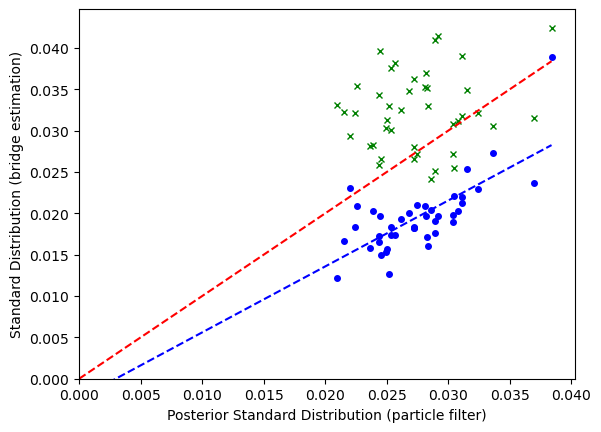

In [163]:
plt.plot(std_pf, std_B, 'ob', ms=4)
plt.plot(std_pf, std_MSD, 'xg', ms=4)
low_end = 0.0 * std_pf.min()
plt.plot([low_end, std_pf.max()], [low_end, std_pf.max()], '--r')
slope, intercept = np.polyfit(std_pf, std_B, 1)
x_ = np.linspace(low_end, std_pf.max())
y_ = slope * x_ + intercept
plt.plot(x_, y_, '--b')
plt.xlim((low_end, None))
plt.ylim((low_end, None))
plt.xlabel("Posterior Standard Distribution (particle filter)")
plt.ylabel("Standard Distribution (bridge estimation)")

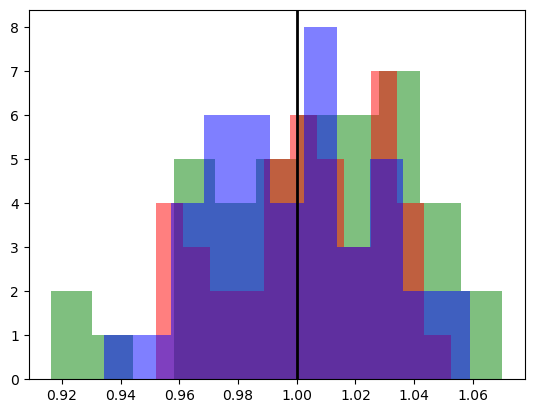

In [167]:
mean_B = np.array([d['mean'] for d in RES_B])
bins = 11
plt.hist(mean_MSD, color='g', alpha=0.5, bins=bins)
plt.hist(mean_pf, color='r', alpha=0.5, bins=bins)
plt.hist(mean_B, color='b', alpha=0.5, bins=bins)
plt.axvline(1, c='k', lw=2)

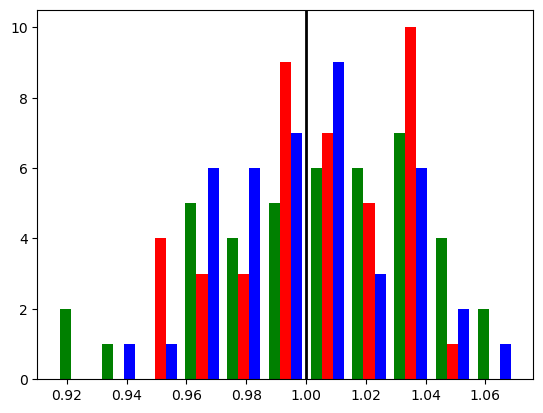

In [166]:
mean_B = np.array([d['mean'] for d in RES_B])
bins = 11
plt.hist([mean_MSD,mean_pf,mean_B], color=['g','r','b'], alpha=1.0, bins=bins)

plt.axvline(1, c='k', lw=2)

In [193]:
def bootstrap_mean(arr, n_samples=None, resampling_count=None):
    """
    Calculate the mean and standard deviation of bootstrap samples from an array.

    Parameters:
    arr (np.ndarray): Input array to resample.
    n_samples (int, optional): Number of bootstrap samples to generate. Default is 1000.
    resampling_count (int, optional): Number of elements in each resampling. Default is len(arr).

    Returns:
    tuple: Mean and standard deviation of the bootstrap sample means.
    """
    if n_samples is None:
        n_samples = 1000  # Default to 1000 bootstrap samples
    
    if resampling_count is None:
        resampling_count = len(arr)  # Default to sampling with replacement of the same size as arr
    
    # Check if the array is empty
    if len(arr) == 0:
        raise ValueError("Input array must not be empty.")

    # Bootstrap resampling
    sample_means = []
    for _ in range(n_samples):
        resampled = np.random.choice(arr, size=resampling_count, replace=True)
        sample_means.append(np.mean(resampled))

    # Calculate mean and standard deviation of the sample means
    bootstrap_mean = np.mean(sample_means)
    bootstrap_std = np.std(sample_means)

    return bootstrap_mean, bootstrap_std

0.02646273976961546
0.02646273976961546
0.02646273976961546


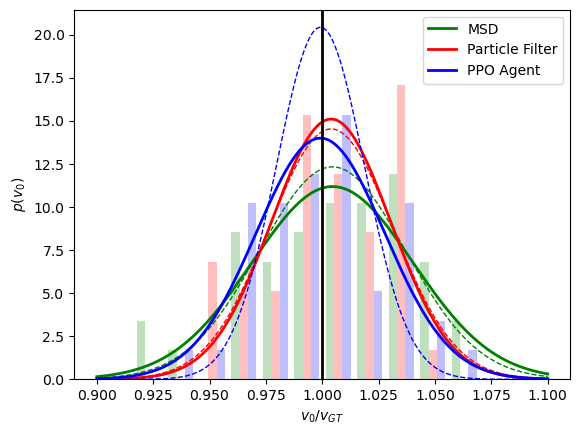

In [192]:
hist_data = [mean_MSD, mean_pf, mean_B]
std_data  = [std_MSD, std_pf, std_B]
colors = ['g', 'r', 'b']
labels = ['MSD', 'Particle Filter', 'PPO Agent']
histograms = []

plt.hist([mean_MSD,mean_pf,mean_B], color=['g','r','b'], alpha=0.25, bins=bins, density=True)

for data in hist_data:
    hist, bin_edges = np.histogram(data, bins=bins, density=True)
    histograms.append((hist, bin_edges))


# Fit Gaussian distributions and plot PDF lines
for data, data_std, color, label in zip(hist_data, std_data, colors, labels):
    mean, std = norm.fit(data)  # Fit Gaussian
    x = np.linspace(0.9, 1.1, 1000)
    pdf = norm.pdf(x, mean, std)  # Compute PDF
    plt.plot(x, pdf, color=color, lw=2, label=label)
    print(np.mean(std_data))
    pdf = norm.pdf(x, mean, np.mean(data_std))  # Compute PDF
    plt.plot(x, pdf, color=color, lw=1, ls='--')

plt.axvline(1, c='k', lw=2)
plt.xlabel(r"$v_0/v_{GT}$")
plt.ylabel("$p(v_0)$")
plt.legend()

In [196]:
print("MSD offset:", bootstrap_mean(np.sqrt(((1 - mean_MSD)**2))))
print("Bridge offset:", bootstrap_mean(np.sqrt(((1 - mean_B)**2))))
print("PF offset:", bootstrap_mean(np.sqrt(((1 - mean_pf)**2))))

MSD offset: (0.029528930419396485, 0.003193467496918022)
Bridge offset: (0.023701557718799598, 0.002445430254304962)
PF offset: (0.022297576041538824, 0.0023396291083712197)


In [147]:
print("MSD overconfidence:", np.sqrt(((1 - mean_MSD)**2).mean()) / std_MSD.mean())
print("Bridge overconfidence:", np.sqrt(((1 - mean_B)**2).mean()) / std_B.mean())
print("PF overconfidence:", np.sqrt(((1 - mean_pf)**2).mean()) / std_pf.mean())

MSD overconfidence: 1.1109896135314945
Bridge overconfidence: 1.460124034728931
PF overconfidence: 0.9723694442780264


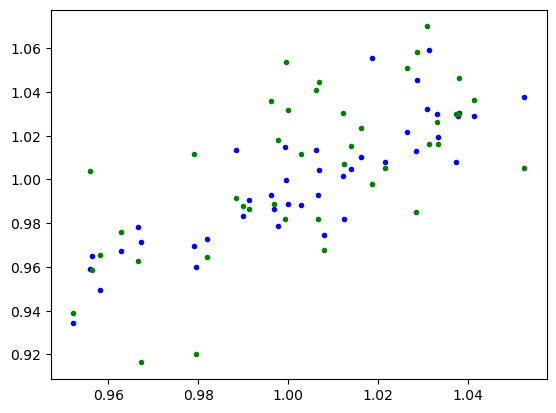

In [162]:
plt.plot(mean_pf, mean_B, '.b')
#plt.plot(mean_MSD, mean_B, '.')
plt.plot(mean_pf, mean_MSD, '.g')